# Week 02 - 훈련 데이터와 테스트 데이터

1주차에서 사용한 도미와 빙어 데이터를 기반으로  
훈련 세트와 테스트 세트를 나누고 샘플링 편향을 확인한다.

In [1]:
# 1주차에서 사용한 데이터

bream_length = [
    25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7,
    30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0,
    32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0,
    34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0,
    36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0
]

bream_weight = [
    242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0,
    390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0,
    600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0,
    685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0,
    850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0
]

smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8,
    11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0
]

smelt_weight = [
    6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0,
    9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9
]

# 도미,빙어 데이터를 하나의 리스트로 만듦
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

# 길이와 무데를 하나씩 가져와서 튜플로 묶는다
fish_data = [[l,w] for l, w in zip(length,weight)]

#정답데이터
fish_target = [1]*35 + [0]*14


## 2-1. 데이터 다루기

머신러닝 모델을 훈련하는 데이터와  
훈련된 모델의 성능을 평가하는 데이터를 분리하여 사용한다.

In [2]:
# 전체 데이터 중에 앞에 35개를 훈련데이터로 사용한다
# 뒤에 14개를 테스트 데이터로 사용한다

# 0~34까지
train_input = fish_data[:35]
train_target = fish_target[:35]

# 35~49까지
test_input = fish_data[35:]
test_target = fish_target[35:]

In [5]:
# k-최근접 이웃 분류기를 생성한다.
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()

# 훈련 데이터로 모델을 학습시킨다.
kn.fit(train_input, train_target)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](1,)",[1]
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
# 테스트 데이터로 모델의 정확도를 확인한다.
kn.score(test_input, test_target)

0.0

## NumPy를 이용한 데이터 처리

데이터를 NumPy 배열로 변환한 뒤  
인덱스를 섞어서 훈련 데이터와 테스트 데이터를 나눈다.

In [7]:
# NumPy 라이브러리를 np라는 이름으로 불러온다.
import numpy as np

# 기존 Python 리스트를 NumPy 배열로 변환한다.
input_arr = np.array(fish_data)
target_arr = np.array(fish_target)

In [ ]:
# numpy 배열로 변환
print(input_arr)
print(target_arr)

[[  25.4  242. ]
 [  26.3  290. ]
 [  26.5  340. ]
 [  29.   363. ]
 [  29.   430. ]
 [  29.7  450. ]
 [  29.7  500. ]
 [  30.   390. ]
 [  30.   450. ]
 [  30.7  500. ]
 [  31.   475. ]
 [  31.   500. ]
 [  31.5  500. ]
 [  32.   340. ]
 [  32.   600. ]
 [  32.   600. ]
 [  33.   700. ]
 [  33.   700. ]
 [  33.5  610. ]
 [  33.5  650. ]
 [  34.   575. ]
 [  34.   685. ]
 [  34.5  620. ]
 [  35.   680. ]
 [  35.   700. ]
 [  35.   725. ]
 [  35.   720. ]
 [  36.   714. ]
 [  36.   850. ]
 [  37.  1000. ]
 [  38.5  920. ]
 [  38.5  955. ]
 [  39.5  925. ]
 [  41.   975. ]
 [  41.   950. ]
 [   9.8    6.7]
 [  10.5    7.5]
 [  10.6    7. ]
 [  11.     9.7]
 [  11.2    9.8]
 [  11.3    8.7]
 [  11.8   10. ]
 [  11.8    9.9]
 [  12.     9.8]
 [  12.2   12.2]
 [  12.4   13.4]
 [  13.    12.2]
 [  14.3   19.7]
 [  15.    19.9]]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0]


In [9]:
# NumPy 배열의 형태(shape)를 확인한다.
print(input_arr.shape)
print(target_arr.shape)

(49, 2)
(49,)


In [10]:
# 랜덤 결과를 항상 동일하게 만들기 위해 seed를 지정한다.
np.random.seed(42)

# 0부터 48까지의 인덱스를 생성한다.
index = np.arange(49)
print(index)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48]


In [11]:
# 0~48의 인덱스 순서를 무작위로 섞는다.
np.random.shuffle(index)
print(index)

[13 45 47 44 17 27 26 25 31 19 12  4 34  8  3  6 40 41 46 15  9 16 24 33
 30  0 43 32  5 29 11 36  1 21  2 37 35 23 39 10 22 18 48 20  7 42 14 28
 38]


In [13]:
# 섞인 인덱스 중 앞의 35개를 이용해 훈련 데이터를 만든다.
train_input = input_arr[index[:35]]
train_target = target_arr[index[:35]]

# 남은 14개의 인덱스로 테스트 데이터를 만든다.
test_input = input_arr[index[35:]]
test_target = target_arr[index[35:]]

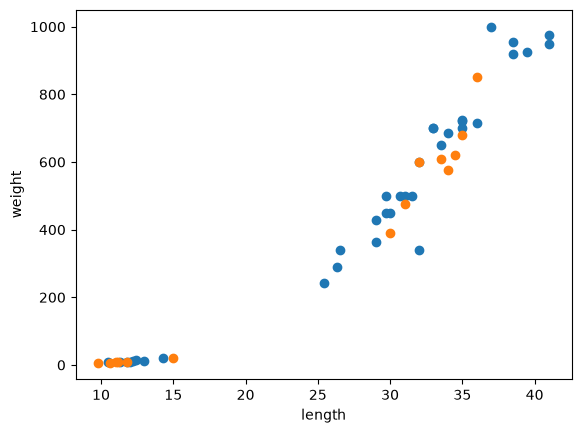

In [ ]:
# 훈련 데이터와 테스트 데이터를 산점도로 확인한다.

import matplotlib.pyplot as plt

# : -> 모든행, 0 -> 첫번째열 모든 생선의 길이
plt.scatter(train_input[:, 0], train_input[:, 1])
plt.scatter(test_input[:, 0], test_input[:, 1])

plt.xlabel('length')
plt.ylabel('weight')

plt.show()

In [15]:
# 테스트 데이터의 실제 정답을 확인한다.
print(test_target)

[0 0 1 0 1 1 1 0 1 1 0 1 1 0]


In [16]:
# 테스트 데이터를 모델에 넣어 예측 결과를 확인한다.
kn.predict(test_input)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [17]:
kn.fit(train_input, train_target)
kn.score(test_input, test_target)

1.0